<a href="https://colab.research.google.com/github/luisferdm6/03-china-mexico-trade-audit/blob/main/01_china_mexico_trade_asymmetry_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bilateral Trade Asymmetries & Customs Risk Audit: China – Mexico (2023–2025)
### Mirror Trade Statistics Analysis for Tariff Gap and Undervaluation Detection

**Analyst:** Luis Fernando Duardo Medina  
**Methodology:** Mirror Trade Statistics (UN Comtrade / WCO)  
**Tech Stack:** DuckDB (SQL), Pandas, Seaborn, Matplotlib

## 1. Environment Setup & Data Ingestion
Load the analytical stack and ingest the official UN Comtrade bilateral trade dataset covering Harmonized System (HS) Chapters 64, 84, and 85 across the 2023–2025 period.

In [2]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import ticker

# Load official UN Comtrade dataset
raw_trade_df = pd.read_csv("comtrade_china_mexico.csv", index_col=False)
print(f"Dataset dimensions: {raw_trade_df.shape}")

# Filter core analytical columns
clean_trade_df = raw_trade_df[['refYear', 'flowDesc', 'cmdCode', 'primaryValue']].copy()
clean_trade_df.head()

Dataset dimensions: (18, 47)


,refYear,flowDesc,cmdCode,primaryValue
0,2023,Import,64,765147704
1,2023,Import,84,21701094738
2,2023,Import,85,39829628491
3,2023,Export,64,983645
4,2023,Export,84,551449072


## 2. Relational OLAP Aggregations with DuckDB (SQL)
Execute in-memory SQL queries to aggregate macro trade flows, compute cumulative chapter balances, and construct the annual bilateral time series.

In [3]:
# Macro aggregation by trade flow direction (Imports vs. Exports)
flow_summary_df = duckdb.sql("""
SELECT
    flowDesc AS trade_flow,
    SUM(primaryValue) AS total_value_usd
FROM clean_trade_df
GROUP BY flowDesc
""").df()

flow_summary_df

,trade_flow,total_value_usd
0,Import,2.035462e+11
1,Export,4.515367e+09


In [4]:
# Cumulative bilateral trade balance by HS chapter (2023-2025)
chapter_balance_df = duckdb.sql("""
SELECT
    cmdCode AS chapter,
    SUM(CASE WHEN flowDesc = 'Import' THEN primaryValue ELSE 0 END) AS imports_usd,
    SUM(CASE WHEN flowDesc = 'Export' THEN primaryValue ELSE 0 END) AS exports_usd,
    exports_usd - imports_usd AS trade_balance_usd
FROM clean_trade_df
GROUP BY cmdCode
ORDER BY chapter ASC
""").df()

chapter_balance_df

,chapter,imports_usd,exports_usd,trade_balance_usd
0,64,2.269195e+09,1.708209e+06,-2.267487e+09
1,84,7.370048e+10,1.506250e+09,-7.219423e+10
2,85,1.275765e+11,3.007409e+09,-1.245691e+11


In [5]:
# Annual bilateral trade balance breakdown by HS chapter and year
trade_data = duckdb.sql("""
SELECT
    cmdCode AS chapter,
    refYear AS year,
    SUM(CASE WHEN flowDesc = 'Import' THEN primaryValue ELSE 0 END) AS imports_usd,
    SUM(CASE WHEN flowDesc = 'Export' THEN primaryValue ELSE 0 END) AS exports_usd,
    exports_usd - imports_usd AS trade_balance_usd
FROM clean_trade_df
GROUP BY cmdCode, refYear
ORDER BY chapter ASC, year ASC
""").df()

# Compute bilateral import-to-export asymmetry ratio
trade_data['asymmetry_ratio'] = trade_data['imports_usd'] / trade_data['exports_usd']
trade_data

,chapter,year,imports_usd,exports_usd,trade_balance_usd,asymmetry_ratio
0,64,2023,7.651477e+08,9.836450e+05,-7.641641e+08,777.869764
1,64,2024,8.972727e+08,5.431690e+05,-8.967295e+08,1651.921708
2,64,2025,6.067750e+08,1.813950e+05,-6.065936e+08,3345.048144
3,84,2023,2.170109e+10,5.514491e+08,-2.114965e+10,39.352854
4,84,2024,2.535762e+10,4.989269e+08,-2.485869e+10,50.824312
5,84,2025,2.664177e+10,4.558735e+08,-2.618589e+10,58.441137
6,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.190022
7,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.319489
8,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.301481


## 3. Severity Ranking & Executive Summary Export
Evaluate relative trade asymmetry vs. absolute monetary deficit and export the formatted executive summary to CSV.

In [6]:
# Top records ranked by relative asymmetry ratio (Imports per $1 USD Exported)
trade_data.sort_values(by='asymmetry_ratio', ascending=False).head()

,chapter,year,imports_usd,exports_usd,trade_balance_usd,asymmetry_ratio
2,64,2025,6.067750e+08,181395.0,-6.065936e+08,3345.048144
1,64,2024,8.972727e+08,543169.0,-8.967295e+08,1651.921708
0,64,2023,7.651477e+08,983645.0,-7.641641e+08,777.869764
5,84,2025,2.664177e+10,455873537.0,-2.618589e+10,58.441137
4,84,2024,2.535762e+10,498926899.0,-2.485869e+10,50.824312


In [7]:
# Rank by largest monetary trade deficit and export executive summary table
executive_report_df = trade_data.sort_values(by='trade_balance_usd', ascending=True).copy()

executive_report_df['deficit_b_usd'] = (executive_report_df['trade_balance_usd'] / 1e9).round(2)
executive_report_df['asymmetry_ratio'] = executive_report_df['asymmetry_ratio'].round(1)
executive_report_df['deficit_b_usd'] = executive_report_df['deficit_b_usd'].map(
    lambda x: f"-${abs(x):.2f} B" if x < 0 else f"${x:.2f} B"
)

executive_report_df.to_csv("china_mexico_trade_audit_summary.csv", index=False)
executive_report_df[['chapter', 'year', 'deficit_b_usd', 'asymmetry_ratio']].head()

,chapter,year,deficit_b_usd,asymmetry_ratio
8,85,2025,-$44.00 B,46.3
7,85,2024,-$41.81 B,44.3
6,85,2023,-$38.76 B,37.2
5,84,2025,-$26.19 B,58.4
4,84,2024,-$24.86 B,50.8


## 4. Harmonized System (HS) Catalog & Modular Analytical Engine
Define the official Harmonized System 2-digit chapter dictionary alongside reusable functions for executive aggregation, econometric indicator computation (`coverage_ratio_pct`, `normalized_trade_index`), and time-series divergence plotting.

In [8]:
# Official Harmonized System (HS) 2-Digit Tariff Chapter Catalog
HS_TARIFF_CATALOG = {
    1: 'Live animals',
    2: 'Meat and edible meat offal',
    3: 'Fish and crustaceans, molluscs and other aquatic invertebrates',
    4: 'Dairy produce; birds eggs; natural honey',
    5: 'Products of animal origin, not elsewhere specified',
    6: 'Live trees and other plants; bulbs, roots and the like',
    7: 'Edible vegetables and certain roots and tubers',
    8: 'Edible fruit and nuts; peel of citrus fruit or melons',
    9: 'Coffee, tea, mate and spices',
    10: 'Cereals',
    11: 'Products of the milling industry; malt; starches',
    12: 'Oil seeds and oleaginous fruits; industrial or medicinal plants',
    13: 'Lac; gums, resins and other vegetable saps and extracts',
    14: 'Vegetable plaiting materials; vegetable products not elsewhere specified',
    15: 'Animal or vegetable fats and oils and their cleavage products',
    16: 'Preparations of meat, of fish or of crustaceans',
    17: 'Sugars and sugar confectionery',
    18: 'Cocoa and cocoa preparations',
    19: 'Preparations of cereals, flour, starch or milk; pastrycooks products',
    20: 'Preparations of vegetables, fruit, nuts or other parts of plants',
    21: 'Miscellaneous edible preparations',
    22: 'Beverages, spirits and vinegar',
    23: 'Residues and waste from the food industries; prepared animal fodder',
    24: 'Tobacco and manufactured tobacco substitutes',
    25: 'Salt; sulphur; earths and stone; plastering materials, lime and cement',
    26: 'Ores, slag and ash',
    27: 'Mineral fuels, mineral oils and products of their distillation',
    28: 'Inorganic chemicals; organic or inorganic compounds of precious metals',
    29: 'Organic chemicals',
    30: 'Pharmaceutical products',
    31: 'Fertilisers',
    32: 'Tanning or dyeing extracts; tannins and their derivatives; pigments',
    33: 'Essential oils and resinoids; perfumery, cosmetic or toilet preparations',
    34: 'Soap, organic surface-active agents, washing preparations, waxes',
    35: 'Albuminoidal substances; modified starches; glues; enzymes',
    36: 'Explosives; pyrotechnic products; matches; pyrophoric alloys',
    37: 'Photographic or cinematographic goods',
    38: 'Miscellaneous chemical products',
    39: 'Plastics and articles thereof',
    40: 'Rubber and articles thereof',
    41: 'Raw hides and skins (other than furskins) and leather',
    42: 'Articles of leather; saddlery and harness; travel goods, handbags',
    43: 'Furskins and artificial fur; manufactures thereof',
    44: 'Wood and articles of wood; wood charcoal',
    45: 'Cork and articles of cork',
    46: 'Manufactures of straw, of esparto or of other plaiting materials',
    47: 'Pulp of wood or of other fibrous cellulosic material; recovered paper',
    48: 'Paper and paperboard; articles of paper pulp, of paper or of paperboard',
    49: 'Printed books, newspapers, pictures and other products of the printing industry',
    50: 'Silk',
    51: 'Wool, fine or coarse animal hair; horsehair yarn and woven fabric',
    52: 'Cotton',
    53: 'Other vegetable textile fibres; paper yarn and woven fabrics of paper yarn',
    54: 'Man-made filaments; strip and the like of man-made textile materials',
    55: 'Man-made staple fibres',
    56: 'Wadding, felt and nonwovens; special yarns; twine, cordage, ropes',
    57: 'Carpets and other textile floor coverings',
    58: 'Special woven fabrics; tufted textile fabrics; lace; tapestries',
    59: 'Impregnated, coated, covered or laminated textile fabrics',
    60: 'Knitted or crocheted fabrics',
    61: 'Articles of apparel and clothing accessories, knitted or crocheted',
    62: 'Articles of apparel and clothing accessories, not knitted or crocheted',
    63: 'Other made up textile articles; sets; worn clothing and worn textile articles',
    64: 'Footwear, gaiters and the like; parts of such articles',
    65: 'Headgear and parts thereof',
    66: 'Umbrellas, sun umbrellas, walking-sticks, seat-sticks, whips',
    67: 'Prepared feathers and down and articles made of feathers or of down',
    68: 'Articles of stone, plaster, cement, asbestos, mica or similar materials',
    69: 'Ceramic products',
    70: 'Glass and glassware',
    71: 'Natural or cultured pearls, precious or semi-precious stones, precious metals',
    72: 'Iron and steel',
    73: 'Articles of iron or steel',
    74: 'Copper and articles thereof',
    75: 'Nickel and articles thereof',
    76: 'Aluminium and articles thereof',
    78: 'Lead and articles thereof',
    79: 'Zinc and articles thereof',
    80: 'Tin and articles thereof',
    81: 'Other base metals; cermets; articles thereof',
    82: 'Tools, implements, cutlery, spoons and forks, of base metal',
    83: 'Miscellaneous articles of base metal',
    84: 'Nuclear reactors, boilers, machinery and mechanical appliances; parts thereof',
    85: 'Electrical machinery and equipment and parts thereof; electronics',
    86: 'Railway or tramway locomotives, rolling-stock and parts thereof',
    87: 'Vehicles other than railway or tramway rolling-stock, and parts',
    88: 'Aircraft, spacecraft, and parts thereof',
    89: 'Ships, boats and floating structures',
    90: 'Optical, photographic, cinematographic, measuring, medical instruments',
    91: 'Clocks and watches and parts thereof',
    92: 'Musical instruments; parts and accessories of such articles',
    93: 'Arms and ammunition; parts and accessories thereof',
    94: 'Furniture; bedding, mattresses; lamps and lighting fittings',
    95: 'Toys, games and sports requisites; parts and accessories thereof',
    96: 'Miscellaneous manufactured articles',
    97: 'Works of art, collectors pieces and antiques'
}

In [9]:
def generate_executive_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Aggregate multi-year trade volume and rank chapters by absolute trade deficit."""
    required_cols = {'chapter', 'imports_usd', 'exports_usd'}
    if not required_cols.issubset(df.columns):
        missing = required_cols - set(df.columns)
        print(f"SCHEMA ERROR: Missing required columns: {missing}")
        return pd.DataFrame()

    summary = (
        df.groupby('chapter')[['imports_usd', 'exports_usd']]
        .sum()
        .reset_index()
    )

    summary['trade_balance_usd'] = summary['exports_usd'] - summary['imports_usd']
    summary['asymmetry_ratio'] = (summary['imports_usd'] / summary['exports_usd']).round(2)
    summary['normalized_trade_index'] = (
        summary['trade_balance_usd']
        / (summary['exports_usd'] + summary['imports_usd'])
    ).round(4)

    return summary.sort_values('trade_balance_usd').reset_index(drop=True)


def calculate_trade_metrics(df: pd.DataFrame, chapter: int) -> pd.DataFrame:
    """Compute annual trade diagnostic metrics for a specific Harmonized System chapter."""
    required_cols = {'chapter', 'year', 'imports_usd', 'exports_usd'}
    if not required_cols.issubset(df.columns):
        missing = required_cols - set(df.columns)
        print(f"SCHEMA ERROR: Missing required columns: {missing}")
        return pd.DataFrame()

    if chapter not in df['chapter'].values:
        available = sorted(df['chapter'].unique().tolist())
        print(f"DATA ERROR: Chapter {chapter} not found. Available chapters: {available}")
        return pd.DataFrame()

    metrics = df[df['chapter'] == chapter].copy()

    metrics['trade_balance_usd'] = metrics['exports_usd'] - metrics['imports_usd']
    metrics['asymmetry_ratio'] = (metrics['imports_usd'] / metrics['exports_usd']).round(2)
    metrics['coverage_ratio_pct'] = (
        (metrics['exports_usd'] / metrics['imports_usd']) * 100
    ).round(2)
    metrics['normalized_trade_index'] = (
        metrics['trade_balance_usd']
        / (metrics['exports_usd'] + metrics['imports_usd'])
    ).round(4)

    return metrics.sort_values('year').reset_index(drop=True)

In [10]:
def plot_trade_divergence(
    df: pd.DataFrame,
    chapter: int,
    domestic_country: str = 'Mexico',
    partner_country: str = 'China',
    catalog: dict[int, str] = HS_TARIFF_CATALOG
) -> None:
    """
    Plot bilateral imports vs. exports time series and net trade balance divergence.

    Dynamically selects the monetary scale (Millions or Billions of USD), shades the
    cumulative trade balance (deficit or surplus), and exports a high-resolution PNG.
    """
    if not isinstance(df, pd.DataFrame):
        print("INPUT ERROR: Argument 'df' must be a Pandas DataFrame.")
        return

    required_cols = {'chapter', 'year', 'imports_usd', 'exports_usd'}
    if not required_cols.issubset(df.columns):
        missing = required_cols - set(df.columns)
        print(f"SCHEMA ERROR: Missing required columns: {missing}")
        return

    if not isinstance(chapter, int):
        print("INPUT ERROR: 'chapter' must be an integer (e.g., 85).")
        return

    if chapter not in df['chapter'].values:
        available = sorted(df['chapter'].unique().tolist())
        print(f"DATA ERROR: Chapter {chapter} not found. Available chapters: {available}")
        return

    subset = df[df['chapter'] == chapter].sort_values('year').copy()
    description = f" ({catalog.get(chapter)})" if catalog and chapter in catalog else ""

    in_millions = max(subset['imports_usd'].max(), subset['exports_usd'].max()) < 1e9
    divisor = 1e6 if in_millions else 1e9
    unit_suffix = 'M' if in_millions else 'B'

    is_surplus = subset['exports_usd'].sum() >= subset['imports_usd'].sum()
    balance_color = '#2ca02c' if is_surplus else '#d62728'
    balance_label = 'Trade Surplus' if is_surplus else 'Trade Deficit'

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        subset['year'],
        subset['imports_usd'],
        marker='o',
        linewidth=2,
        color='#1f77b4',
        label=f'Imports ({partner_country} -> {domestic_country})'
    )
    ax.plot(
        subset['year'],
        subset['exports_usd'],
        marker='s',
        linewidth=2,
        color='#2ca02c',
        label=f'Exports ({domestic_country} -> {partner_country})'
    )
    ax.fill_between(
        subset['year'],
        subset['exports_usd'],
        subset['imports_usd'],
        color=balance_color,
        alpha=0.12,
        label=balance_label
    )

    ax.set_title(
        f'Bilateral Trade Divergence - HS Chapter {chapter}{description}',
        fontsize=12,
        fontweight='bold'
    )
    ax.set_xlabel('Year', fontsize=11)
    ax.set_xticks(subset['year'].unique())
    ax.set_ylabel(f'Trade Value ({unit_suffix} USD)', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(frameon=True)

    formatter = ticker.FuncFormatter(lambda x, pos: f'${x / divisor:.1f}{unit_suffix}')
    ax.yaxis.set_major_formatter(formatter)

    plt.tight_layout()
    fig.savefig(f'trade_divergence_ch{chapter}.png', dpi=300, bbox_inches='tight')
    plt.show()

## 5. Automated Audit Pipeline & Sectoral Divergence Visualization
Execute the end-to-end audit pipeline to automatically detect the highest-deficit HS chapter, display its historical econometric indicators, and render the bilateral divergence plots across all audited sectors.

,chapter,imports_usd,exports_usd,trade_balance_usd,asymmetry_ratio,normalized_trade_index
0,85,1.275765e+11,3.007409e+09,-1.245691e+11,42.42,-0.9539
1,84,7.370048e+10,1.506250e+09,-7.219423e+10,48.93,-0.9599
2,64,2.269195e+09,1.708209e+06,-2.267487e+09,1328.41,-0.9985



CRITICAL SECTOR DETECTED: HS Chapter 85 (Electrical machinery and equipment and parts thereof; electronics)

=== HISTORICAL METRICS: HS CHAPTER 85 ===


,chapter,year,imports_usd,exports_usd,trade_balance_usd,asymmetry_ratio,coverage_ratio_pct,normalized_trade_index
0,85,2023,3.982963e+10,1.070976e+09,-3.875865e+10,37.19,2.69,-0.9476
1,85,2024,4.277251e+10,9.650949e+08,-4.180742e+10,44.32,2.26,-0.9559
2,85,2025,4.497440e+10,9.713383e+08,-4.400306e+10,46.30,2.16,-0.9577


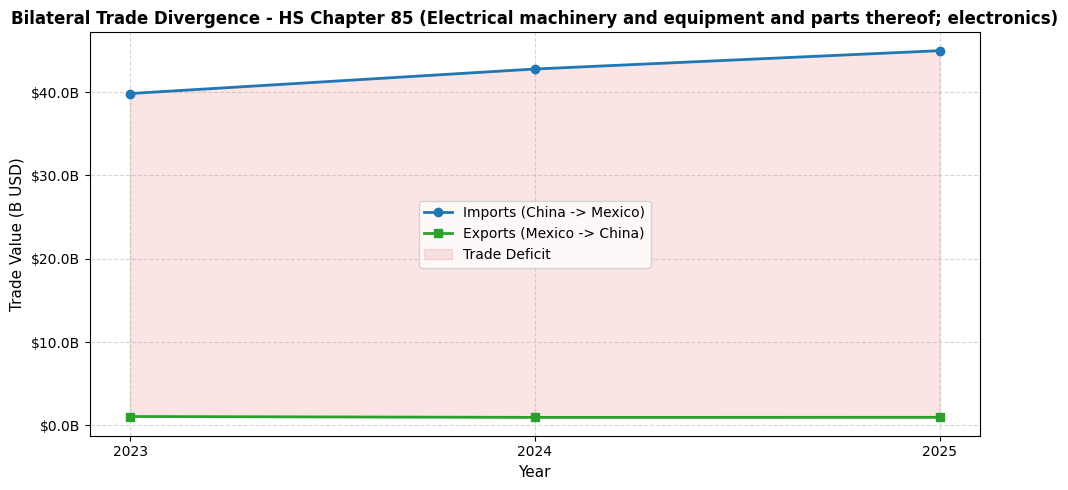

In [11]:
# 1. Generate multi-year executive summary and automatically identify critical deficit chapter
summary_df = generate_executive_summary(trade_data)
display(summary_df)

critical_chapter = int(summary_df.iloc[0]['chapter'])
print(f"\nCRITICAL SECTOR DETECTED: HS Chapter {critical_chapter} ({HS_TARIFF_CATALOG.get(critical_chapter)})")

# 2. Compute and display annual econometric metrics for the critical chapter
critical_metrics_df = calculate_trade_metrics(trade_data, critical_chapter)
print(f"\n=== HISTORICAL METRICS: HS CHAPTER {critical_chapter} ===")
display(critical_metrics_df)

# 3. Render and export divergence plot for the critical sector (HS Chapter 85)
plot_trade_divergence(trade_data, critical_chapter)

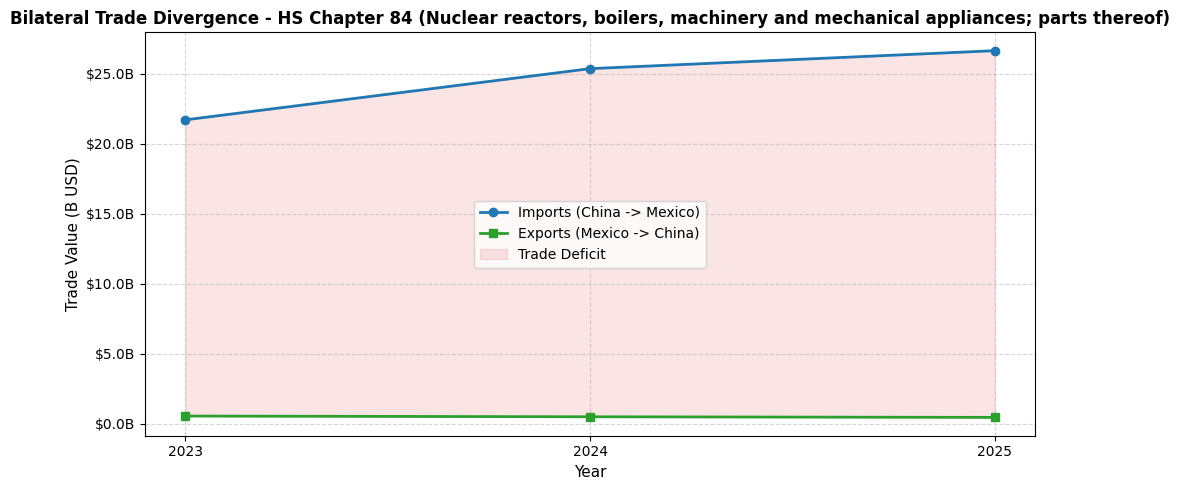

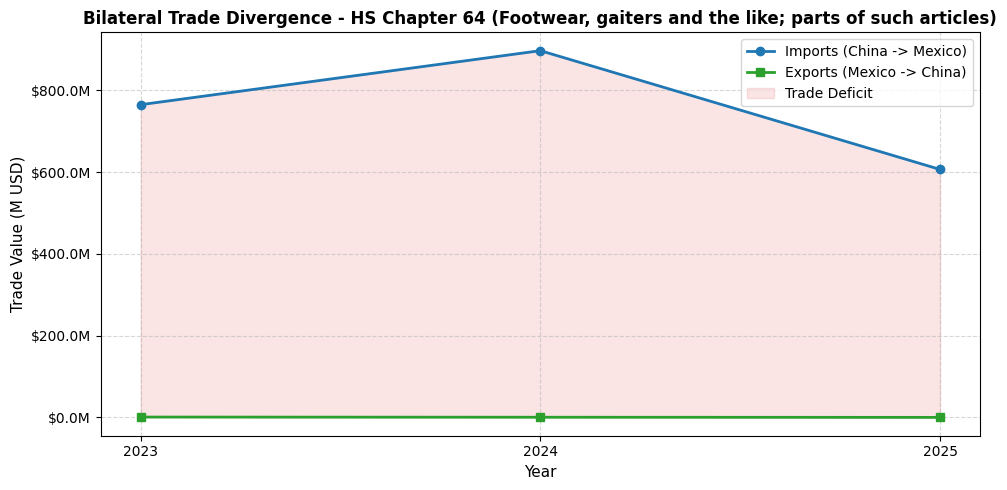

In [12]:
# Comparative divergence analysis for Capital Goods (HS Chapter 84) and Footwear (HS Chapter 64)
plot_trade_divergence(trade_data, 84)
plot_trade_divergence(trade_data, 64)